# newest version config

In [ ]:
import torch, transformers, datasets, platform

print("Torch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Python:", platform.python_version())
print("GPU:", torch.cuda.get_device_name(0))


Torch: 2.9.0+cu128
CUDA: 12.8
Transformers: 5.0.0
Datasets: 4.0.0
Python: 3.12.12
GPU: NVIDIA A100-SXM4-80GB


# older version config

In [ ]:
import torch, transformers, datasets, platform

print("Torch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Python:", platform.python_version())
print("GPU:", torch.cuda.get_device_name(0))


Torch: 2.9.0+cu126
CUDA: 12.6
Transformers: 4.57.6
Datasets: 4.0.0
Python: 3.12.12
GPU: NVIDIA A100-SXM4-80GB


# using latest colab version lets test with transformer older version

In [ ]:
!pip install transformers==4.57.6


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 120.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 61.1 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.5.0
    Uninstalling huggingface_hub-1.5.0:
      Successfully uninstalled huggingface_hub-1.5.0
  Attempting uninstall: transformers
    Found existing installation: transformers 5.0.0
    Uninstalling transformers-5.0.0:
      Successfully uninstalled transformers-5.0.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r /content/drive/MyDrive/deep-past-initiative-machine-translation.zip  /content/deep-past-initiative-machine-translation.zip

In [ ]:
!unzip /content/deep-past-initiative-machine-translation.zip

Archive:  /content/deep-past-initiative-machine-translation.zip
  inflating: OA_Lexicon_eBL.csv      
  inflating: Sentences_Oare_FirstWord_LinNum.csv  
  inflating: bibliography.csv        
  inflating: eBL_Dictionary.csv      
  inflating: publications.csv        
  inflating: published_texts.csv     
  inflating: resources.csv           
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [ ]:
!cp -r /content/drive/MyDrive/archive.zip  /content/archive.zip

In [ ]:
!unzip /content/archive.zip

Archive:  /content/archive.zip
  inflating: google_madlad400_3b_mt_finetuned_corrected/config.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/generation_config.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model-00001-of-00003.safetensors  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model-00002-of-00003.safetensors  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model-00003-of-00003.safetensors  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model.safetensors.index.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/rng_state.pth  
  inflating: google_madlad400_3b_mt_finetuned_corrected/scheduler.pt  
  inflating: google_madlad400_3b_mt_finetuned_corrected/special_tokens_map.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/spiece.model  
  inflating: google_madlad400_3b_mt_finetuned_corrected/tokenizer.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/tokenizer_config.json  
  inflati

In [ ]:
import pandas as pd

tr = pd.read_csv('/content/train.csv')
tr['text_combined'] = tr['translation']+''+tr['transliteration']
print(tr['translation'].dropna().str.len().max())
print(tr['transliteration'].dropna().str.len().max())
print(tr['text_combined'].dropna().str.len().max())


3895
932
4787


In [ ]:
df = tr[
    (tr['transliteration'].str.len() <= 640) &
    (tr['translation'].str.len() <= 768)
]

print(df.shape)

(1169, 4)


In [ ]:
tr.shape

(1561, 4)

In [ ]:
tr.columns

Index(['oare_id', 'transliteration', 'translation'], dtype='object')

In [ ]:
translation_max  = tr.loc[tr['translation'].str.len().idxmax(), 'translation']
transliteration_max  = tr.loc[tr['transliteration'].str.len().idxmax(), 'transliteration']

print(translation_max)
print(transliteration_max)

As to the 4 minas of silver that Enna-Suen owed to our father, 2.5 minas of silver, interest, 0.5 mina, expenses on the 5 minas of silver, I received from Enna-Suen. 1 mina of silver furthermore that Ennam-Adad owed I received at the same time from Enna-Suen. When I wrote to Warad-ilī in Kuburnat and ... When I wrote to Katila(?) to Amur-... and ... 4 shekels of silver ... x mina silver ... Šad-ahšu ... 1 mina 5 shekels of silver owed by ...; 0.3333 mina of silver owed by ... x mina of silver ... I received  from the man of Tumliya; 1 mina of silver owed by Ušhata's son; 2.5 mina of silver owed by Ikūn-pīya son of ...; 1 talent of -copper owed by Shorty"; also Shorty gave me a slave-girl and left her with Ah-šalim. I have not yet received Šimašitiša. In all: 30 minas 3 shekels of silver apart from the copper I received from the oustanding claims of my father. 6 minas 15 shekels ... the previous ... 0.5 ... I paid to the office of the colony; 1.5 mina of refined silver under my seal, 10

Loading datasets...

Train dataset shape: (1561, 3)
Test dataset shape: (4, 5)

Train columns: ['oare_id', 'transliteration', 'translation']

Sample training data:
                                oare_id  \
0  004a7dbd-57ce-46f8-9691-409be61c676e   
1  0064939c-59b9-4448-a63d-34612af0a1b5   
2  0073f2c0-524c-4bbf-915a-8c1772a4fb98   

                                     transliteration  \
0  KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-(d)IM KIŠI...   
1               1 TÚG ša qá-tim i-tur₄-DINGIR il₅-qé   
2  TÚG u-la i-dí-na-ku-um i-tù-ra-ma 9 GÍN KÙ.BABBAR   

                                         translation  
0  Seal of Mannum-balum-Aššur son of Ṣilli-Adad, ...  
1  Itūr-ilī has received one textile of ordinary ...  
2  ... he did not give you a textile. He returned...  

Loading MADLAD400 tokenizer...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]


Tokenizing data to analyze length distribution...

TOKEN LENGTH STATISTICS

📊 SOURCE (Transliteration) Token Lengths:
  Mean:   265.07
  Median: 228.00
  Std:    165.97
  Min:    17
  Max:    635
  75th percentile: 393
  90th percentile: 540
  95th percentile: 553
  99th percentile: 580

📊 TARGET (Translation) Token Lengths:
  Mean:   157.85
  Median: 123.00
  Std:    144.43
  Min:    4
  Max:    1267
  75th percentile: 211
  90th percentile: 317
  95th percentile: 415
  99th percentile: 717

RECOMMENDED MAX_LENGTH SETTINGS

✅ Recommended MAX_LENGTH (covers 95% of data): 553
   - This will truncate ~5% of samples
   - Good balance between coverage and efficiency

⚠️  Conservative MAX_LENGTH (covers 99% of data): 717
   - This will truncate only ~1% of samples
   - Uses more memory but better coverage

🔥 Aggressive MAX_LENGTH (covers 90% of data): 540
   - Fastest training, lowest memory
   - May truncate important content

OUTLIER ANALYSIS

Samples with source length > 95th percentile

/tmp/ipython-input-1631029989.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])



✅ Visualization saved as 'token_length_distribution.png'


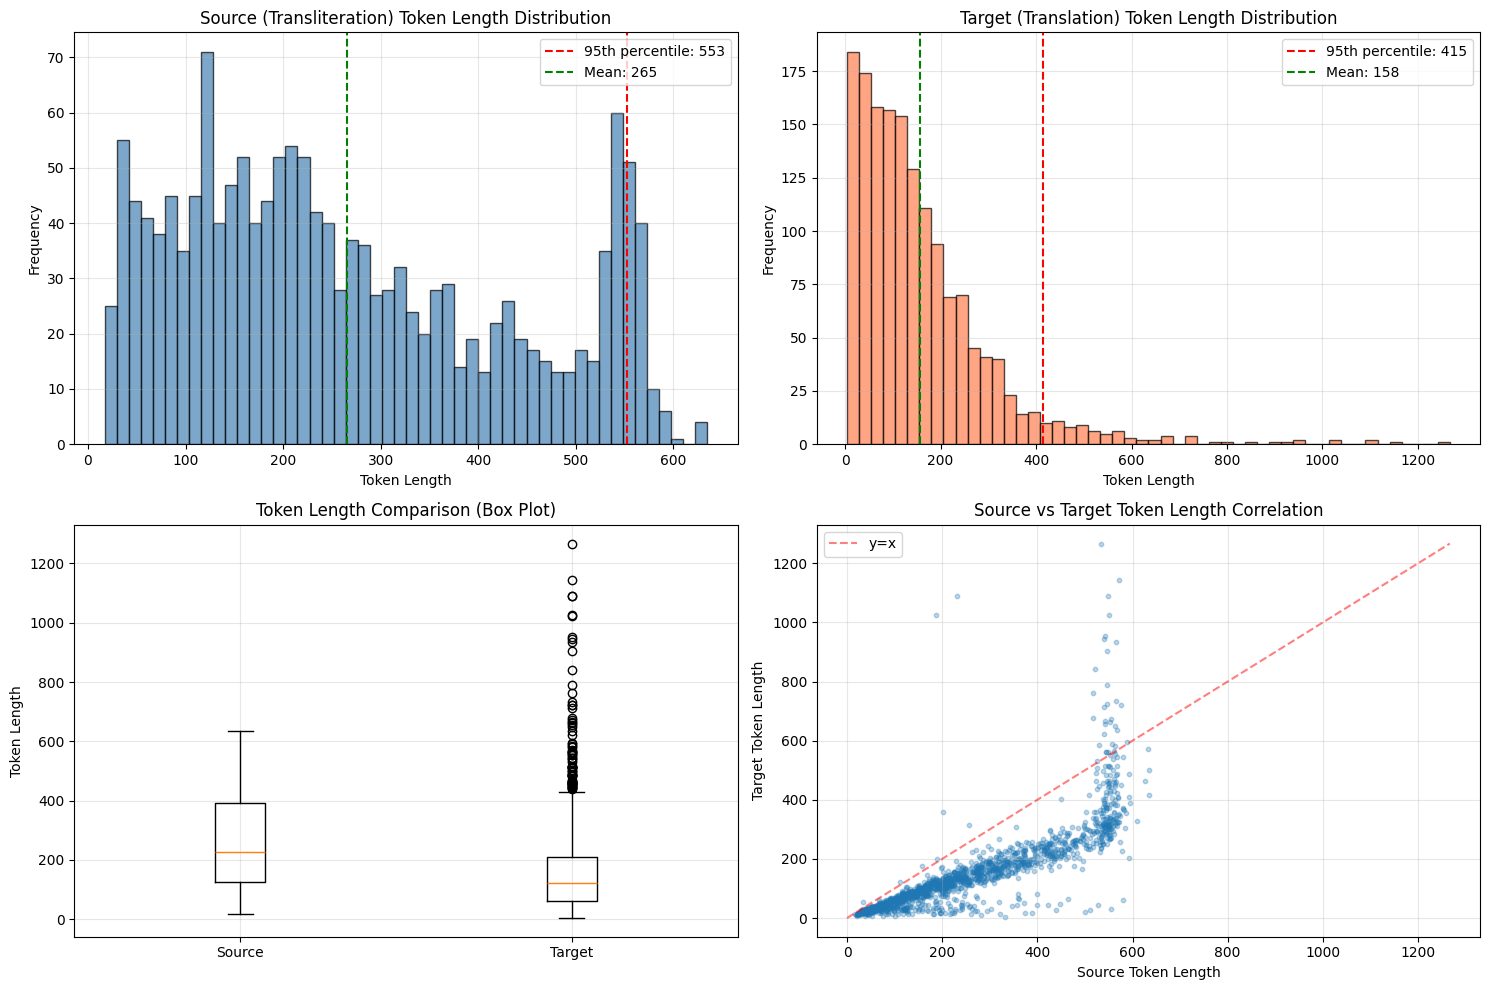


SUMMARY & RECOMMENDATIONS

Based on the analysis:

1. Use MAX_LENGTH = 553 in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - ⚠️  Consider adjusting based on your data

3. Samples that will be truncated at 512 tokens:
   - Source: 222 samples (14.22%)
   - Target: 44 samples (2.82%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "google/madlad400-3b-mt"
INPUT_DIR = "/content/"
TRAIN_CSV = f"{INPUT_DIR}/train.csv"
TEST_CSV = f"{INPUT_DIR}/test.csv"

# ==================== 1. LOAD DATA ====================
print("Loading datasets...")
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)

print(f"\nTrain dataset shape: {train.shape}")
print(f"Test dataset shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")

# Display sample data
print("\n" + "="*50)
print("Sample training data:")
print("="*50)
print(train.head(3))

# ==================== 2. LOAD TOKENIZER ====================
print("\n" + "="*50)
print("Loading MADLAD400 tokenizer...")
print("="*50)
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)

# MADLAD400 uses language code prefix (e.g., "<2en>" for English target)
PREFIX = "<2en> "

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("\nTokenizing data to analyze length distribution...")

# Tokenize source (transliteration) with prefix
source_lengths = train['transliteration'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# Tokenize target (translation)
target_lengths = train['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS ====================
print("\n" + "="*50)
print("TOKEN LENGTH STATISTICS")
print("="*50)

print("\n📊 SOURCE (Transliteration) Token Lengths:")
print(f"  Mean:   {source_lengths.mean():.2f}")
print(f"  Median: {source_lengths.median():.2f}")
print(f"  Std:    {source_lengths.std():.2f}")
print(f"  Min:    {source_lengths.min()}")
print(f"  Max:    {source_lengths.max()}")
print(f"  75th percentile: {source_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {source_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {source_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {source_lengths.quantile(0.99):.0f}")

print("\n📊 TARGET (Translation) Token Lengths:")
print(f"  Mean:   {target_lengths.mean():.2f}")
print(f"  Median: {target_lengths.median():.2f}")
print(f"  Std:    {target_lengths.std():.2f}")
print(f"  Min:    {target_lengths.min()}")
print(f"  Max:    {target_lengths.max()}")
print(f"  75th percentile: {target_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {target_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {target_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {target_lengths.quantile(0.99):.0f}")

# ==================== 5. RECOMMENDED MAX_LENGTH ====================
print("\n" + "="*50)
print("RECOMMENDED MAX_LENGTH SETTINGS")
print("="*50)

# Calculate suggested max_length based on percentiles
source_95 = int(source_lengths.quantile(0.95))
target_95 = int(target_lengths.quantile(0.95))
source_99 = int(source_lengths.quantile(0.99))
target_99 = int(target_lengths.quantile(0.99))

suggested_max_length = max(source_95, target_95)
conservative_max_length = max(source_99, target_99)

print(f"\n✅ Recommended MAX_LENGTH (covers 95% of data): {suggested_max_length}")
print(f"   - This will truncate ~5% of samples")
print(f"   - Good balance between coverage and efficiency")

print(f"\n⚠️  Conservative MAX_LENGTH (covers 99% of data): {conservative_max_length}")
print(f"   - This will truncate only ~1% of samples")
print(f"   - Uses more memory but better coverage")

print(f"\n🔥 Aggressive MAX_LENGTH (covers 90% of data): {max(int(source_lengths.quantile(0.90)), int(target_lengths.quantile(0.90)))}")
print(f"   - Fastest training, lowest memory")
print(f"   - May truncate important content")

# ==================== 6. CHECK OUTLIERS ====================
print("\n" + "="*50)
print("OUTLIER ANALYSIS")
print("="*50)

# Find samples with very long sequences
threshold = source_lengths.quantile(0.95)
long_sources = train[source_lengths > threshold]

print(f"\nSamples with source length > 95th percentile ({threshold:.0f} tokens): {len(long_sources)}")
if len(long_sources) > 0:
    print("\nExamples of long transliterations:")
    for idx in long_sources.head(3).index:
        src_len = source_lengths.iloc[idx]
        print(f"\n  Index {idx} (Length: {src_len} tokens):")
        print(f"  {train.loc[idx, 'transliteration'][:200]}...")

# ==================== 7. VISUALIZATIONS ====================
print("\n" + "="*50)
print("GENERATING VISUALIZATIONS")
print("="*50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Source length distribution
axes[0, 0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(source_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {source_lengths.quantile(0.95):.0f}')
axes[0, 0].axvline(source_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {source_lengths.mean():.0f}')
axes[0, 0].set_xlabel('Token Length')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Source (Transliteration) Token Length Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Target length distribution
axes[0, 1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(target_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {target_lengths.quantile(0.95):.0f}')
axes[0, 1].axvline(target_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {target_lengths.mean():.0f}')
axes[0, 1].set_xlabel('Token Length')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Target (Translation) Token Length Distribution')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot comparison
data_to_plot = [source_lengths, target_lengths]
axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])
axes[1, 0].set_ylabel('Token Length')
axes[1, 0].set_title('Token Length Comparison (Box Plot)')
axes[1, 0].grid(alpha=0.3)

# Scatter plot: source vs target length
axes[1, 1].scatter(source_lengths, target_lengths, alpha=0.3, s=10)
axes[1, 1].set_xlabel('Source Token Length')
axes[1, 1].set_ylabel('Target Token Length')
axes[1, 1].set_title('Source vs Target Token Length Correlation')
axes[1, 1].grid(alpha=0.3)

# Add diagonal reference line
max_val = max(source_lengths.max(), target_lengths.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', alpha=0.5, label='y=x')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('token_length_distribution.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved as 'token_length_distribution.png'")
plt.show()

# ==================== 8. SUMMARY ====================
print("\n" + "="*50)
print("SUMMARY & RECOMMENDATIONS")
print("="*50)
print(f"""
Based on the analysis:

1. Use MAX_LENGTH = {suggested_max_length} in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - {'✅ This is sufficient!' if 512 >= suggested_max_length else '⚠️  Consider adjusting based on your data'}

3. Samples that will be truncated at 512 tokens:
   - Source: {(source_lengths > 512).sum()} samples ({(source_lengths > 512).sum() / len(source_lengths) * 100:.2f}%)
   - Target: {(target_lengths > 512).sum()} samples ({(target_lengths > 512).sum() / len(target_lengths) * 100:.2f}%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.
""")

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 10.3 MB/s eta 0:00:00


In [ ]:
!pip install sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 13.2 MB/s eta 0:00:00


In [ ]:
!pip install -U kagglehub


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.5/160.5 kB 20.2 MB/s eta 0:00:00
  Attempting uninstall: kagglehub
    Found existing installation: kagglehub 0.3.13
    Uninstalling kagglehub-0.3.13:
      Successfully uninstalled kagglehub-0.3.13


In [ ]:
import kagglehub
print(kagglehub.__version__)


1.0.0


In [ ]:
import kagglehub
import os

# ⚠️ Better practice: use secrets, but keeping your example intact
os.environ["KAGGLE_USERNAME"] = "ravikshdikola"
os.environ["KAGGLE_KEY"] = "apply token here"

# 👇 Force kagglehub cache to Colab filesystem
#os.environ["KAGGLEHUB_CACHE_DIR"] = "/content/kagglehub"

# # Download dataset
path = kagglehub.dataset_download("ravikshdikola/dpc2-exp2")

print("Dataset downloaded to:", path)


100%|██████████| 10.2G/10.2G [07:59<00:00, 22.8MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/ravikshdikola/dpc2-exp2/versions/1


In [ ]:
!cp -r /root/.cache/kagglehub/datasets/ravikshdikola/dpc2-exp2/versions/1   /content/madlab-ak/

In [ ]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset("cipher-ling/akkadian")
# This takes the list of dictionaries and turns keys into column headers
df_train = pd.DataFrame(ds['train']['translation'])
df_val = pd.DataFrame(ds['validation']['translation'])
df_test = pd.DataFrame(ds['test']['translation'])

df = pd.concat([df_train, df_val, df_test])
df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
df = df.drop(['ak'],axis=1)
df.to_csv('cipher-ling.csv',index=False)



ds_1 = load_dataset("phucthaiv02/akkadian-translation")
df_train_1 = pd.DataFrame(ds_1['train'])
df_val_1 = pd.DataFrame(ds_1['validation'])
df_1 = pd.concat([df_train_1, df_val_1])
df_1.to_csv('phucthaiv02.csv',index=False)

ds_2 = load_dataset("phucthaiv02/akkadian_english_sentences_alignment")
df_train_2 = pd.DataFrame(ds_2['train'])
df_2 = df_train_2.copy()
df_2.to_csv('phucthaiv02_sentences_alignment.csv',index=False)

ds_3 = load_dataset("phucthaiv02/akkadian_english_sentences_alignment_2")
df_train_3 = pd.DataFrame(ds_3['train'])
df_3 = df_train_3.copy()
df_3.to_csv('phucthaiv02_english_sentences_alignment_2.csv',index=False)
tr = pd.read_csv('/content/train.csv')

df_fi = pd.concat([df, df_2, df_1, df_3])
#df_fi = df_fi.drop_duplicates(subset='transliteration', keep='first').reset_index(drop=True)

df_final = pd.concat([tr, df_fi])
df_final = df_final.sample(frac=1, random_state=42).reset_index(drop=True)

df_final.to_csv('/content/final_train.csv',index=False)


print(tr.shape)
print(df.shape)
print(df_1.shape)
print(df_2.shape)
print(df_3.shape)
print(df_final.shape)



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.57M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/430k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50478 [00:00<?, ? examples/s]

... (10 outputs left out)

README.md:   0%|          | 0.00/325 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/842k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10677 [00:00<?, ? examples/s]

(1561, 3)
(56160, 2)
(74214, 4)
(10314, 2)
(10677, 2)
(152926, 5)


In [ ]:
import os
import gc
import re
import unicodedata
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate


# ==========================================
# CONFIGURATION
# ==========================================

class Config:
    MODEL_NAME = "/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/"
    MAX_LENGTH = 576
    BATCH_SIZE = 4
    EPOCHS = 2
    LEARNING_RATE = 5e-5
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    GRADIENT_ACCUMULATION_STEPS = 4
    USE_GRADIENT_CHECKPOINTING = True
    FP16 = False


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()

INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")


# ==========================================
# SHARED SENTINELS & LOOKUP TABLES
# ==========================================

_GAP_SENTINEL    = '\x02GAP\x02'
_BIG_SENTINEL    = '\x02BIG\x02'
_HYPHEN_SENTINEL = '\x02HYP\x02'

_FROM_SUBSCRIPT = str.maketrans("₀₁₂₃₄₅₆₇₈₉", "0123456789")

# Roman numeral months — longest match first to avoid partial hits
_ROMAN_MONTHS = [
    (r'\bmonth\s+XII\b',  'month 12'),
    (r'\bmonth\s+XI\b',   'month 11'),
    (r'\bmonth\s+VIII\b', 'month 8'),
    (r'\bmonth\s+VII\b',  'month 7'),
    (r'\bmonth\s+IX\b',   'month 9'),
    (r'\bmonth\s+VI\b',   'month 6'),
    (r'\bmonth\s+IV\b',   'month 4'),
    (r'\bmonth\s+III\b',  'month 3'),
    (r'\bmonth\s+II\b',   'month 2'),
    (r'\bmonth\s+X\b',    'month 10'),
    (r'\bmonth\s+V\b',    'month 5'),
    (r'\bmonth\s+I\b',    'month 1'),
]

# Strip ONLY [ ] and ʾ ʿ.
# Do NOT strip " ' ( ) — they are legitimate speech/editorial markers
# preserved in both old training data and new evaluation format.
_FORBIDDEN_CHARS = str.maketrans('', '', '[]' '\u02be\u02bf')

_X_PLUS_RE = re.compile(r'\bx\s*\+\s*', re.IGNORECASE)
_X_RE      = re.compile(r'(?<!\w)x(?!\w)', re.IGNORECASE)
_BREAK_RE  = re.compile(
    r'\(\s*(?:large\s+break|\d+\s+broken\s+lines?|break)\s*\)',
    re.IGNORECASE)


# ==========================================
# PRE-PROCESSING  (transliteration)
# ──────────────────────────────────────────
# Training data is in OLD FORMAT:
#   • Determinatives already use parens : (d), (ki), (m)
#   • Gaps use bare x or ellipsis       : x, xx, …, ...
#   • Characters already correct        : ḫ, subscripts, á, à …
#   • Fractions already old-style       : 0.33333, 1.3333300000000001
#   • KÙ.BABBAR already fully spelled out
#
# We must ONLY normalise gap notation into model-token form.
# Everything else is left UNTOUCHED.
#
# After these steps the string is in the same canonical model-input form
# that the inference pipeline produces after its new→old conversion pass.
# ==========================================

def preprocess_input(text: str) -> str:
    """
    Normalise OLD-FORMAT transliteration into canonical model-input form.

    Conversion table
    ----------------
    …  ……  ...  ....  . . .   →  <big_gap>
    xx  xxx  xxxx+ (runs)     →  <big_gap>
    standalone x              →  <gap>
    <gap> adjacent to <gap>   →  <big_gap>   (collapse)

    ḫ, subscripts, accents, (d) determinatives, decimals — NOT touched.
    """
    if pd.isna(text) or not isinstance(text, str):
        return ""
    text = str(text).strip()

    # ── 1. Protect any pre-existing tags (idempotency) ───────────────────
    text = text.replace('<big_gap>', _BIG_SENTINEL)
    text = text.replace('<gap>',     _GAP_SENTINEL)

    # ── 2. Unicode / multi-dot ellipsis → <big_gap> ──────────────────────
    text = re.sub(r'……|…', _BIG_SENTINEL, text)
    text = re.sub(r'\.{3,}', _BIG_SENTINEL, text)
    text = re.sub(r'(?:\.\s+){2,}\.', _BIG_SENTINEL, text)   # ". . ." style

    # ── 3. xx+ runs (multi-sign breaks) → <big_gap> ──────────────────────
    text = re.sub(r'\bxx+\b', _BIG_SENTINEL, text, flags=re.IGNORECASE)

    # ── 4. Standalone x tokens → <gap>  (not inside words like "ixtum") ──
    text = re.sub(r'(?<![A-Za-z\d])x(?![A-Za-z\d])', _GAP_SENTINEL, text)

    # ── 5. Restore sentinels as real tags ────────────────────────────────
    text = text.replace(_BIG_SENTINEL, '<big_gap>')
    text = text.replace(_GAP_SENTINEL, '<gap>')

    # ── 6. Collapse adjacent gaps ─────────────────────────────────────────
    text = re.sub(r'(<big_gap>\s*){2,}', '<big_gap> ', text)
    text = re.sub(r'(<gap>\s*){2,}',     '<gap> ',     text)
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)   # two gaps → big_gap

    # ── 7. Whitespace normalisation ──────────────────────────────────────
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# ==========================================
# POST-PROCESSING  (translation labels)
# ──────────────────────────────────────────
# Direct port of inference pipeline's postprocess_output.
# Ensures training labels live in the exact same token space as inference
# output so ChrF scoring is fully consistent.
#
# Key fixes vs. original training pipeline
# ─────────────────────────────────────────
# ✗ OLD stripped ( ) " ; ! ? indiscriminately
# ✓ NEW strips only [ ] and ʾ ʿ — keeps " ' ( ) as legitimate markers
#
# ✗ OLD converted 0.3333→⅓, 0.5→½, 0.6666→⅔ etc.
# ✓ NEW keeps decimals as-is; only truncates N.83333→N.8333 (⅚-family)
#
# ✗ OLD left [x], [word] in output unresolved
# ✓ NEW resolves: [word]→word, [x]/[...]→<gap>
#
# ✗ OLD did not convert roman month numerals
# ✓ NEW converts month I–XII → month 1–12
#
# ✗ OLD spacing pass broke <gap>-Aššur → " <gap>  -Aššur"
# ✓ NEW uses _HYPHEN_SENTINEL to preserve <gap>-word correctly
# ==========================================

def _normalise_decimals(text: str) -> str:
    """
    Truncate ONLY the ⅚-family (N.83333+) to 4 dp.
    All other decimals (0.3333, 0.5, 0.6666 …) are left untouched.
    NEVER convert any decimal to a unicode fraction character.
    """
    text = re.sub(r'(\d+\.8333)3+', r'\1', text)
    return text


def _resolve_brackets(text: str) -> str:
    """
    Surgically resolve [...] patterns in labels:
      []              → <gap>
      [x] / [...]     → <gap>
      [word]          → word   (editorial supplement — keep content)
      [word + ...]    → word <gap>
      [?]             → (removed)
    """
    def _repl(m):
        inner = m.group(1).strip()
        if not inner:
            return _GAP_SENTINEL
        # Pure gap content: dots, x, digits, +, ?
        if re.fullmatch(r'[\.\sx\+\d\?]*', inner, re.IGNORECASE) and \
                not re.search(r'[a-zA-ZÀ-ÿšŠṣṢṭṬ]',
                               inner.replace('x', '').replace('X', '')):
            return _GAP_SENTINEL
        inner = inner.rstrip('?').strip()
        if not inner:
            return _GAP_SENTINEL
        # Mixed content — replace gap tokens inside, keep real words
        cleaned = re.sub(r'(?i)(?<!\w)x(?!\w)|\.{2,}|…',
                         ' ' + _GAP_SENTINEL + ' ', inner)
        cleaned = re.sub(r'\s+', ' ', cleaned).strip()
        return cleaned if cleaned else _GAP_SENTINEL

    return re.sub(r'\[([^\]]*)\]', _repl, text)


def _remove_phrase_repeats(text: str) -> str:
    """Remove consecutive duplicate phrases of 2–8 words."""
    words = text.split()
    if len(words) < 4:
        return text
    for phrase_len in range(8, 1, -1):
        i = 0
        result, changed = [], False
        while i < len(words):
            if i + phrase_len * 2 <= len(words):
                phrase      = words[i:i + phrase_len]
                next_phrase = words[i + phrase_len:i + phrase_len * 2]
                if phrase == next_phrase:
                    result.extend(phrase)
                    j = i + phrase_len
                    while j + phrase_len <= len(words) and \
                            words[j:j + phrase_len] == phrase:
                        j += phrase_len
                    i = j
                    changed = True
                    continue
            result.append(words[i])
            i += 1
        if changed:
            words = result
    return ' '.join(words)


def postprocess_output(text: str) -> str:
    """
    Convert OLD-FORMAT training translation → canonical label form.

    Conversion table
    ----------------
    x / ... / xxxx+          →  <gap>
    [word]                   →  word
    [x] / [...]              →  <gap>
    (break) / (large break)  →  <gap>
    roman month I–XII        →  month 1–12
    N.83333                  →  N.8333   (5 dp → 4 dp, ⅚-family only)
    0.3333 / 0.5 / 0.6666   →  kept as-is  (no unicode frac conversion)
    ḫ / Ḫ                    →  h / H
    subscript digits         →  ASCII digits
    duplicate phrases        →  deduplicated
    """
    if not isinstance(text, str) or not text.strip():
        return "broken text"

    # ── 0. Protect existing gap tags ─────────────────────────────────────
    text = text.replace('<big_gap>', _BIG_SENTINEL).replace('<gap>', _GAP_SENTINEL)

    # ── 1. (break) / (large break) / (N broken lines) → gap ──────────────
    text = _BREAK_RE.sub(_GAP_SENTINEL, text)

    # ── 2. x+Number → <gap> Number  e.g. "20+x minas" → "<gap> minas" ───
    text = _X_PLUS_RE.sub(_GAP_SENTINEL + ' ', text)

    # ── 3. Multi-dot ellipsis and long-x runs → gap ───────────────────────
    text = re.sub(r'\.{2,}', _GAP_SENTINEL, text)
    text = re.sub(r'…',      _GAP_SENTINEL, text)
    text = re.sub(r'\bxxxx+\b', _GAP_SENTINEL, text, flags=re.IGNORECASE)

    # ── 4. Bracket resolution ─────────────────────────────────────────────
    # Restore real tags temporarily so resolver sees them correctly
    text = text.replace(_GAP_SENTINEL, '<gap>').replace(_BIG_SENTINEL, '<big_gap>')
    text = _resolve_brackets(text)
    text = text.replace('<big_gap>', _BIG_SENTINEL).replace('<gap>', _GAP_SENTINEL)

    # ── 5. Standalone x → gap  (after bracket resolution) ────────────────
    text = _X_RE.sub(_GAP_SENTINEL, text)

    # ── 6. Roman month numbers ───────────────────────────────────────────
    for pattern, replacement in _ROMAN_MONTHS:
        text = re.sub(pattern, replacement, text, flags=re.IGNORECASE)

    # ── 7. Strip [ ] and ʾ ʿ only — preserve " ' ( ) ─────────────────────
    text = text.translate(_FORBIDDEN_CHARS)

    # ── 8. Collapse all gap sentinels → <gap>  (big_gap → <gap> too) ─────
    text = text.replace(_GAP_SENTINEL, '<gap>').replace(_BIG_SENTINEL, '<gap>')

    # ── 9. Protect hyphenated gaps BEFORE spacing normalisation ───────────
    #    <gap>-Aššur must NOT become " <gap>  -Aššur"
    text = re.sub(r'<gap>-(\S)', _GAP_SENTINEL + _HYPHEN_SENTINEL + r'\1', text)
    text = re.sub(r'(\S)-<gap>', r'\1' + _HYPHEN_SENTINEL + _GAP_SENTINEL, text)

    # ── 10. Collapse adjacent standalone gaps ─────────────────────────────
    text = re.sub(r'(?<!\x02)<gap>\s+<gap>(?!\x02)', '<gap>', text)
    text = re.sub(r'(<gap>\s+){3,}', '<gap> ', text)

    # ── 11. Gap spacing (standalone gaps padded with spaces) ──────────────
    text = re.sub(r'\s*<gap>\s*', ' <gap> ', text)

    # ── 12. Restore hyphen sentinels to correct <gap>-word form ───────────
    text = text.replace(' ' + _GAP_SENTINEL + ' ' + _HYPHEN_SENTINEL, '<gap>-')
    text = text.replace(_HYPHEN_SENTINEL + ' ' + _GAP_SENTINEL + ' ', '-<gap>')
    text = text.replace(_GAP_SENTINEL,    '<gap>')
    text = text.replace(_HYPHEN_SENTINEL, '-')

    # ── 13. ḫ / Ḫ → h / H ────────────────────────────────────────────────
    text = text.replace('ḫ', 'h').replace('Ḫ', 'H')

    # ── 14. Subscript digits → ASCII ─────────────────────────────────────
    text = text.translate(_FROM_SUBSCRIPT)

    # ── 15. Decimal normalisation  (N.83333→N.8333 ONLY, no unicode fracs)
    text = _normalise_decimals(text)

    # ── 16. Deduplication ────────────────────────────────────────────────
    text = re.sub(r'\b(\w+)(?:\s+\1\b)+', r'\1', text)
    text = _remove_phrase_repeats(text)

    # ── 17. Gap-punctuation attachment ───────────────────────────────────
    text = re.sub(r'<gap>\s+([",;.:?!])', r'<gap>\1', text)
    text = re.sub(r'(["])\s+<gap>', r'\1<gap>', text)

    # ── 18. Final cleanup ─────────────────────────────────────────────────
    text = re.sub(r'\s+', ' ', text).strip()
    text = re.sub(r'^[-–]+\s*', '', text)
    text = re.sub(r'\s*[-–]+$', '', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text if text else "broken text"


# ==========================================
# APPLY TO TRAINING DATA + SANITY CHECKS
# ==========================================

train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"]     = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")
print("-" * 55)

n_gap      = train_df["transliteration"].str.contains("<gap>",     na=False).sum()
n_bgap     = train_df["transliteration"].str.contains("<big_gap>", na=False).sum()
n_hbar_src = train_df["transliteration"].str.contains("ḫ",        na=False).sum()
n_hbar_tgt = train_df["translation"].str.contains("ḫ",            na=False).sum()
n_frac_tgt = train_df["translation"].str.contains(r"½|⅓|⅔|¼|¾",  na=False).sum()
n_bracket  = train_df["translation"].str.contains(r"\[",          na=False).sum()
n_roman    = train_df["translation"].str.contains(
                 r"\bmonth\s+(?:I|II|III|IV|V|VI|VII|VIII|IX|X|XI|XII)\b",
                 na=False).sum()

print(f"Transliteration rows with <gap>           : {n_gap}")
print(f"Transliteration rows with <big_gap>       : {n_bgap}")
print(f"Transliteration rows with ḫ (expect > 0)  : {n_hbar_src}")
print(f"Translation rows with ḫ     (expect 0)    : {n_hbar_tgt}")
print(f"Translation rows with unicode fracs        : {n_frac_tgt}")
print(f"Translation rows with [ brackets (exp 0)  : {n_bracket}")
print(f"Translation rows with roman months (exp 0): {n_roman}")
print("-" * 55)


# ==========================================
# DATASET + TOKENISATION
# ==========================================

dataset = Dataset.from_pandas(train_df)

tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "


def preprocess_function(examples):
    inputs  = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex)           for ex in examples["translation"]]

    model_inputs = tokenizer(inputs,  max_length=Config.MAX_LENGTH, truncation=True)
    labels       = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs


tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# MODEL + TRAINER SETUP
# ==========================================

gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32,
)

if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")


def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where(
        (preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id
    )

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply the SAME postprocess as training labels — metric space must match
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=9600,
    learning_rate=Config.LEARNING_RATE,

    fp16=Config.FP16,
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    optim="adamw_torch",
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    dataloader_pin_memory=True,
    dataloader_num_workers=2,

    generation_max_length=Config.MAX_LENGTH,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)


print("=" * 60)
print("Starting Training — MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length             : {Config.MAX_LENGTH}")
print(f"Batch Size             : {Config.BATCH_SIZE}")
print(f"Gradient Accumulation  : {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size   : {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate          : {Config.LEARNING_RATE}")
print(f"Epochs                 : {Config.EPOCHS}")
print(f"FP16                   : {Config.FP16}")
print(f"Gradient Checkpointing : {Config.USE_GRADIENT_CHECKPOINTING}")
print("=" * 60)

trainer.train()

trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 152926 sentences
-------------------------------------------------------
Transliteration rows with <gap>           : 4463
Transliteration rows with <big_gap>       : 12406
Transliteration rows with ḫ (expect > 0)  : 8011
Translation rows with ḫ     (expect 0)    : 0
Translation rows with unicode fracs        : 223
Translation rows with [ brackets (exp 0)  : 0
Translation rows with roman months (exp 0): 0
-------------------------------------------------------


The tokenizer you are loading from '/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/152926 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (3 outputs left out)

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,3.129500
20,3.038900
30,2.922500
40,2.864400
50,2.457900
60,2.457800
70,2.638900
80,2.499800
90,2.360000
100,2.265200


Step,Training Loss
10,3.129500
20,3.038900
30,2.922500
40,2.864400
50,2.457900
60,2.457800
70,2.638900
80,2.499800
90,2.360000
100,2.265200



✓ Model saved to ./madlad400-3b-akkadian-final


In [ ]:
!rm -rf /content/madlad400-3b-akkadian-final/checkpoint-19116/optimizer.pt

In [ ]:
# !rm -r /content/madlad400-3b-akkadian-final

rm: cannot remove '/content/madlad400-3b-akkadian-final': No such file or directory


In [ ]:
!rm -r /content/kaggle.json

rm: cannot remove '/content/kaggle.json': No such file or directory


In [ ]:
%%writefile kaggle.json
{
"username":"ravikshdikola","key":"apply token here"
}


Writing kaggle.json


In [ ]:
!rm -rf /content/madlad400-3b-akkadian-final/checkpoint-6558/optimizer.pt

In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
%cd /content/madlad400-3b-akkadian-final/checkpoint-19116/


/content/madlad400-3b-akkadian-final/checkpoint-19116


In [ ]:
%%writefile dataset-metadata.json
{
  "title": "madlab Akkadian retrained_1st_stage_newmix",
  "id": "ravikshdikola/madlab-akkadian-retrained-1st-stage-newmix",
  "licenses": [
    {
      "name": "CC0-1.0"
    }
  ]
}


Writing dataset-metadata.json


In [ ]:
!kaggle datasets create -p .

Starting upload for file tokenizer.json
100% 15.8M/15.8M [00:02<00:00, 5.81MB/s]
Upload successful: tokenizer.json (16MB)
Starting upload for file training_args.bin
100% 5.83k/5.83k [00:00<00:00, 7.46kB/s]
Upload successful: training_args.bin (6KB)
Starting upload for file tokenizer_config.json
100% 996/996 [00:00<00:00, 1.30kB/s]
Upload successful: tokenizer_config.json (996B)
Starting upload for file spiece.model
100% 4.22M/4.22M [00:02<00:00, 1.71MB/s]
Upload successful: spiece.model (4MB)
Starting upload for file rng_state.pth
100% 14.3k/14.3k [00:00<00:00, 19.1kB/s]
Upload successful: rng_state.pth (14KB)
Starting upload for file config.json
100% 799/799 [00:01<00:00, 705B/s]
Upload successful: config.json (799B)
Starting upload for file model-00001-of-00003.safetensors
100% 4.63G/4.63G [03:25<00:00, 24.2MB/s]
Upload successful: model-00001-of-00003.safetensors (5GB)
Starting upload for file trainer_state.json
100% 326k/326k [00:01<00:00, 231kB/s]
Upload successful: trainer_state.